## 1. Import Libraries

In [1]:
! pip install pyarrow

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap
import joblib

e:\BRM003-ML-Project\brmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load UNSW-NB15 Training and Testing Data

In [ ]:
from pathlib import Path

data_dir = Path(r"E:\BRM003-ML-Project\dataset folder\archive (1)")

train_path = data_dir / "UNSW_NB15_training-set.parquet"
test_candidates = [
    data_dir / "UNSW_NB15_test-set.parquet",
    data_dir / "UNSW_NB15_testing-set.parquet",
    data_dir / "UNSW_NB15_test-set.csv",
    data_dir / "UNSW_NB15_testing-set.csv",
]

test_path = next(path for path in test_candidates if path.exists())

train_df = pd.read_parquet(train_path)
test_df = (
    pd.read_parquet(test_path)
    if test_path.suffix == ".parquet"
    else pd.read_csv(test_path)
)

In [ ]:

data_dir = Path(r"E:\BRM003-ML-Project\dataset folder\archive (1)")

train_path = data_dir / "UNSW_NB15_training-set.parquet"
test_candidates = [
    data_dir / "UNSW_NB15_test-set.parquet",
    data_dir / "UNSW_NB15_testing-set.parquet",
    data_dir / "UNSW_NB15_test-set.csv",
    data_dir / "UNSW_NB15_testing-set.csv",
]

test_path = next(path for path in test_candidates if path.exists())

train_df = pd.read_parquet(train_path)
test_df = (
    pd.read_parquet(test_path)
    if test_path.suffix == ".parquet"
    else pd.read_csv(test_path)
)

## 3. Combine / Verify Dataset Structure

In [4]:
train_cols = set(train_df.columns)
test_cols = set(test_df.columns)

print("Columns only in train:", train_cols - test_cols)
print("Columns only in test :", test_cols - train_cols)
print("Column count — train:", len(train_df.columns), "| test:", len(test_df.columns))

Columns only in train: set()
Columns only in test : set()
Column count — train: 36 | test: 36


In [5]:
dtype_mismatch = {}
for col in train_cols & test_cols:
    if train_df[col].dtype != test_df[col].dtype:
        dtype_mismatch[col] = (train_df[col].dtype, test_df[col].dtype)

print("Dtype mismatches between train/test (col: (train_dtype, test_dtype)):")
print(dtype_mismatch if dtype_mismatch else "None — dtypes are consistent.")

Dtype mismatches between train/test (col: (train_dtype, test_dtype)):
{'state': (CategoricalDtype(categories=['CON', 'ECO', 'FIN', 'INT', 'PAR', 'REQ', 'RST', 'URN',
                  'no'],
, ordered=False, categories_dtype=str), CategoricalDtype(categories=['ACC', 'CLO', 'CON', 'FIN', 'INT', 'REQ', 'RST'], ordered=False, categories_dtype=str)), 'proto': (CategoricalDtype(categories=['3pc', 'a/n', 'aes-sp3-d', 'any', 'argus', 'aris', 'arp',
                  'ax.25', 'bbn-rcc', 'bna',
                  ...
                  'visa', 'vmtp', 'vrrp', 'wb-expak', 'wb-mon', 'wsn', 'xnet',
                  'xns-idp', 'xtp', 'zero'],
, ordered=False, categories_dtype=str), CategoricalDtype(categories=['3pc', 'a/n', 'aes-sp3-d', 'any', 'argus', 'aris', 'arp',
                  'ax.25', 'bbn-rcc', 'bna',
                  ...
                  'visa', 'vmtp', 'vrrp', 'wb-expak', 'wb-mon', 'wsn', 'xnet',
                  'xns-idp', 'xtp', 'zero'],
, ordered=False, categories_dtype=str))}


In [6]:
# UNSW-NB15 ships an 'id' column that is just a row identifier, not a feature —
# confirm it exists here so Step 8 knows to drop it.
print("'id' column present:", "id" in train_df.columns)

'id' column present: False


## 4. Dataset Overview

In [7]:
train_df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,0,0,2,1,0,0,0,0,Normal,0


In [8]:
test_df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.000011,udp,-,INT,2,0,496,0,90909.09375,180363632.0,...,0,0,1,1,0,0,0,0,Normal,0
1,0.000008,udp,-,INT,2,0,1762,0,125000.00000,881000000.0,...,0,0,1,1,0,0,0,0,Normal,0
2,0.000005,udp,-,INT,2,0,1068,0,200000.00000,854400000.0,...,0,0,1,1,0,0,0,0,Normal,0
3,0.000006,udp,-,INT,2,0,900,0,166666.65625,600000000.0,...,0,0,2,1,0,0,0,0,Normal,0
4,0.000010,udp,-,INT,2,0,2126,0,100000.00000,850400000.0,...,0,0,2,1,0,0,0,0,Normal,0


In [9]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 36 columns):
 #   Column             Non-Null Count   Dtype   
---  ------             --------------   -----   
 0   dur                175341 non-null  float32 
 1   proto              175341 non-null  category
 2   service            175341 non-null  category
 3   state              175341 non-null  category
 4   spkts              175341 non-null  int16   
 5   dpkts              175341 non-null  int16   
 6   sbytes             175341 non-null  int32   
 7   dbytes             175341 non-null  int32   
 8   rate               175341 non-null  float32 
 9   sload              175341 non-null  float32 
 10  dload              175341 non-null  float32 
 11  sloss              175341 non-null  int16   
 12  dloss              175341 non-null  int16   
 13  sinpkt             175341 non-null  float32 
 14  dinpkt             175341 non-null  float32 
 15  sjit               175341 non-null  float32 


In [10]:
train_df.shape

(175341, 36)

In [11]:
train_df.describe()

,dur,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,...,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,175341.000000,1.753410e+05,1.753410e+05,175341.000000,175341.000000,...,175341.000000,175341.000000,1.753410e+05,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,95406.179688,7.345403e+07,6.712056e+05,4.953000,6.948010,...,124.173382,0.105982,2.144292e+03,5.383538,4.206255,0.014948,0.014948,0.133066,0.015752,0.680622
std,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,165400.968750,1.883574e+08,2.421312e+06,66.005059,52.732999,...,258.317056,0.776911,5.420797e+04,8.047104,5.783585,0.126048,0.126048,0.701208,0.124516,0.466237
min,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,32.786140,1.305334e+04,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3225.806641,8.796748e+05,1.447023e+03,0.000000,0.000000,...,44.000000,0.000000,0.000000e+00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,125000.000000,8.888889e+07,2.784487e+04,3.000000,2.000000,...,89.000000,0.000000,0.000000e+00,5.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1000000.000000,5.988000e+09,2.242273e+07,4803.000000,5484.000000,...,1458.000000,172.000000,6.558056e+06,51.000000,46.000000,4.000000,4.000000,30.000000,1.000000,1.000000


In [12]:
train_df.dtypes.value_counts()

float32     11
int16        9
int8         7
int32        3
int64        2
category     1
category     1
category     1
category     1
Name: count, dtype: int64

## 5. Data Quality

In [13]:
train_df.isnull().sum().sort_values(ascending=False)

dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
is_sm_ips_ports      0
attack_cat           0
label                0
dtype: int64

In [14]:
test_df.isnull().sum().sum()

np.int64(0)

In [15]:
dup_count = train_df.duplicated().sum()
print("Duplicate rows found:", dup_count)

Duplicate rows found: 78519


**Fix:** the original notebook only *counted* duplicates and left a "remove duplicate data" to-do note — this cell now actually drops them.

In [16]:
before = train_df.shape[0]
train_df = train_df.drop_duplicates().reset_index(drop=True)
after = train_df.shape[0]
print(f"Dropped {before - after} duplicate rows ({before} -> {after})")

Dropped 78519 duplicate rows (175341 -> 96822)


In [17]:
numeric_cols_check = train_df.select_dtypes(include=[np.number]).columns
inf_counts = np.isinf(train_df[numeric_cols_check]).sum()
inf_counts = inf_counts[inf_counts > 0]

print("Columns containing infinite values:")
print(inf_counts if not inf_counts.empty else "None found.")

Columns containing infinite values:
None found.


In [18]:
# Replace any infinite values (if present) so they don't silently propagate into scaling/modeling
train_df[numeric_cols_check] = train_df[numeric_cols_check].replace([np.inf, -np.inf], np.nan)
train_df[numeric_cols_check] = train_df[numeric_cols_check].fillna(train_df[numeric_cols_check].median())

test_numeric_cols_check = test_df.select_dtypes(include=[np.number]).columns
test_df[test_numeric_cols_check] = test_df[test_numeric_cols_check].replace([np.inf, -np.inf], np.nan)
test_df[test_numeric_cols_check] = test_df[test_numeric_cols_check].fillna(test_df[test_numeric_cols_check].median())

In [19]:
# Invalid / inconsistent values: flag numeric columns that contain negatives
# (durations, byte counts, packet counts, etc. should never be negative in UNSW-NB15)
negative_counts = (train_df[numeric_cols_check] < 0).sum()
negative_counts = negative_counts[negative_counts > 0]

print("Numeric columns with negative values (review before assuming they're errors):")
print(negative_counts if not negative_counts.empty else "None found.")

Numeric columns with negative values (review before assuming they're errors):
None found.


## 6. Exploratory Data Analysis

In [20]:
train_df["label"].value_counts()

label
0    48894
1    47928
Name: count, dtype: int64

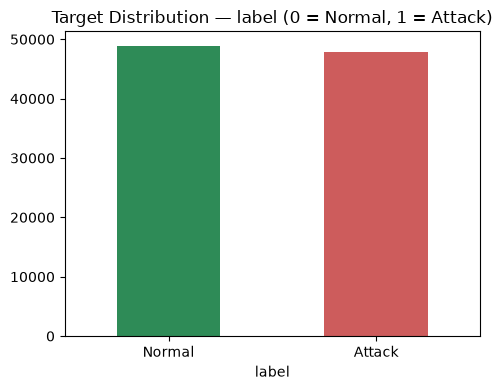

In [21]:
plt.figure(figsize=(5, 4))
train_df["label"].value_counts().plot(kind="bar", color=["seagreen", "indianred"])
plt.title("Target Distribution — label (0 = Normal, 1 = Attack)")
plt.xticks([0, 1], ["Normal", "Attack"], rotation=0)
plt.tight_layout()
plt.show()

In [22]:
train_df["attack_cat"].value_counts()

attack_cat
Normal            48894
Exploits          19360
Fuzzers           14082
Reconnaissance     6000
DoS                3369
Generic            1800
Backdoor           1121
Analysis           1119
Shellcode           954
Worms               123
Name: count, dtype: int64

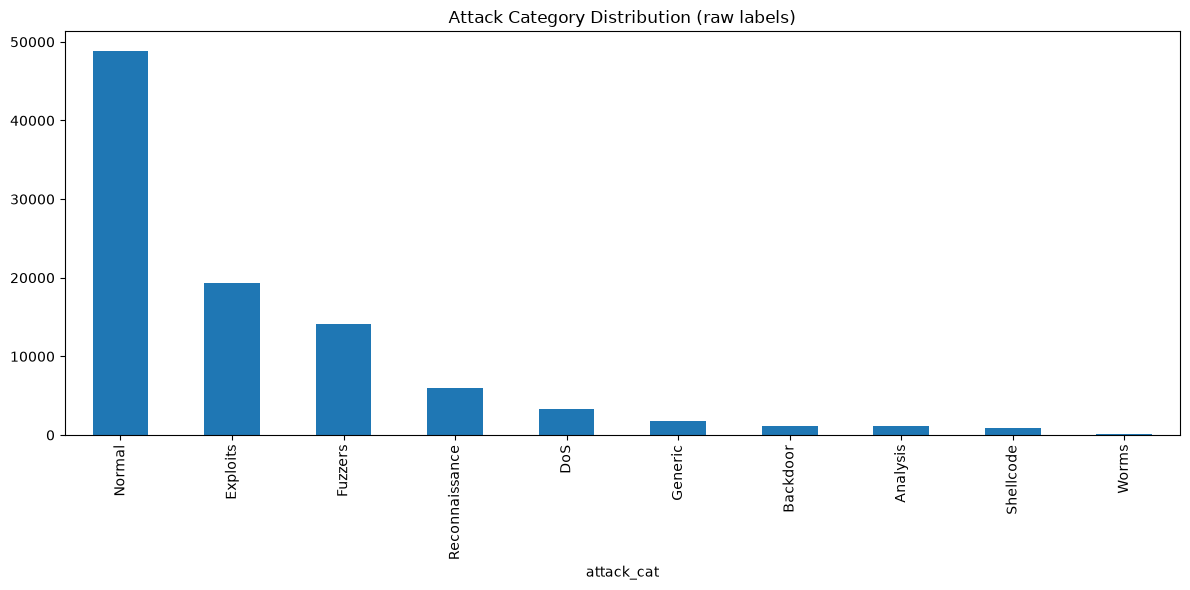

In [23]:
plt.figure(figsize=(12, 6))
train_df["attack_cat"].value_counts().plot(kind="bar")
plt.title("Attack Category Distribution (raw labels)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

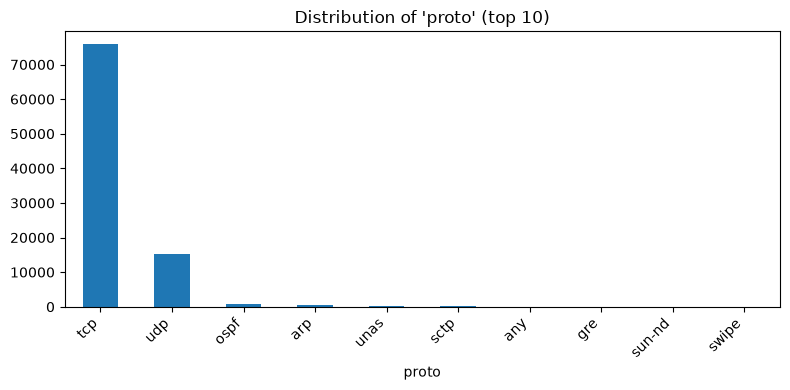

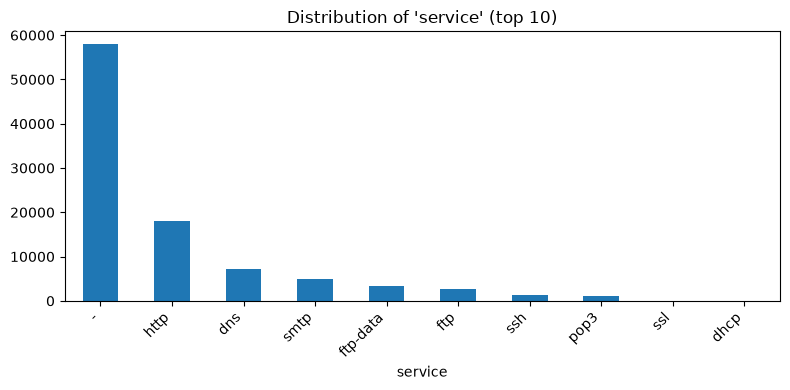

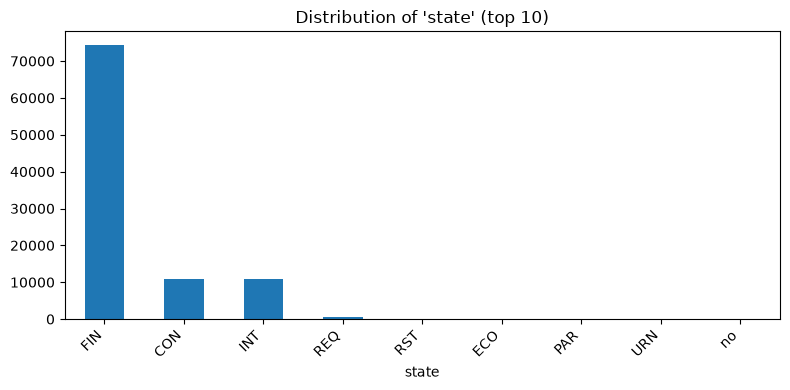

In [24]:
categorical_preview_cols = [
    c
    for c in train_df.select_dtypes(include=["object", "category"]).columns
    if c not in {"attack_cat", "label"}
]

for col in categorical_preview_cols:
    plt.figure(figsize=(8, 4))
    train_df[col].value_counts().head(10).plot(kind="bar")
    plt.title(f"Distribution of '{col}' (top 10)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

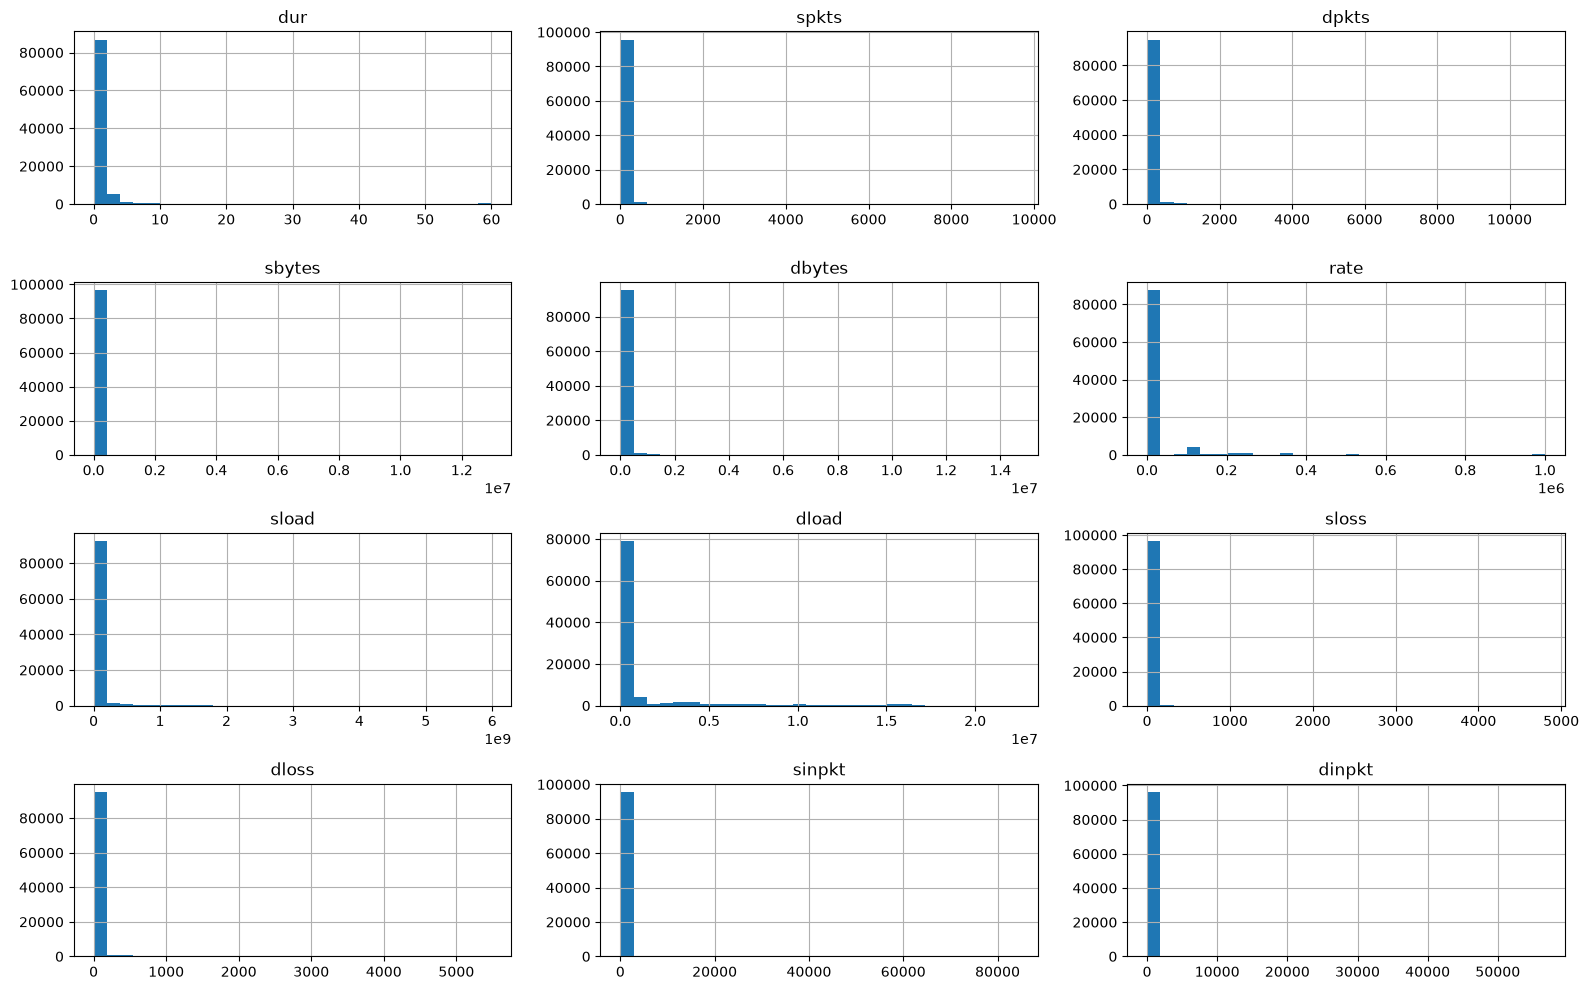

In [25]:
numerical_preview_cols = [
    c for c in train_df.select_dtypes(include=[np.number]).columns
    if c not in ["id", "label"]
][:12]  # first 12 numeric features, to keep the grid readable

train_df[numerical_preview_cols].hist(figsize=(16, 10), bins=30)
plt.tight_layout()
plt.show()

## 7. Define Target

**Scope for this notebook:** binary classification (`Normal` vs `Attack`), matching the filename. UNSW-NB15 already ships a ready-made binary `label` column (0 = Normal, 1 = Attack) — no construction needed, just a sanity check against `attack_cat`. A multiclass notebook (Normal + individual attack categories), built the same way as the NSL-KDD multiclass version, can follow as a separate file if you want it — the same encode → split → scale → SMOTE → model pipeline below applies, just swapping the target and using `f1_macro`/`multi:softprob` as was done for NSL-KDD.

In [26]:
# Sanity check: label should be 0 exactly when attack_cat == "Normal"
cross_check = pd.crosstab(train_df["label"], train_df["attack_cat"] == "Normal")
print(cross_check)

attack_cat  False  True 
label                   
0               0  48894
1           47928      0


## 8. X / y Separation

In [27]:
drop_cols = [c for c in ["id", "attack_cat", "label"] if c in train_df.columns]

X = train_df.drop(columns=drop_cols)
y = train_df["label"]

test_drop_cols = [c for c in ["id", "attack_cat", "label"] if c in test_df.columns]
X_test_raw = test_df.drop(columns=test_drop_cols)
y_test = test_df["label"]

## 9. Identify Data Types

In [28]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(include=[np.number]).columns

print("Categorical columns:", list(categorical_cols))
print("Numerical columns:", list(numerical_cols))

Categorical columns: []
Numerical columns: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports']


## 10. Encode Categorical Features

In [29]:
X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

X_test_raw = pd.get_dummies(X_test_raw, columns=categorical_cols, drop_first=False)
X_test_raw = X_test_raw.reindex(columns=X.columns, fill_value=0)

In [30]:
# Target is already numeric (0/1) for binary classification — LabelEncoder kept here
# only so the same pattern extends cleanly if you add the multiclass target later.
target_encoder = LabelEncoder()
target_encoder.fit(["Normal", "Attack"])

Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Holds the label for each class.","ndarray[<U6](2,)","['Attack','Normal']"


## 11. Train / Validation Split

In [31]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

feature_columns = X_train.columns.tolist()

## 12. Feature Scaling

In [32]:
scaler = StandardScaler()

# Encode categorical columns, including pandas CategoricalDtype columns
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

if categorical_cols:
    X_train = pd.get_dummies(X_train, columns=categorical_cols, dtype=float)
    X_val = pd.get_dummies(X_val, columns=categorical_cols, dtype=float)
    X_test_raw = pd.get_dummies(X_test_raw, columns=categorical_cols, dtype=float)

# Ensure validation and test use exactly the training feature columns
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test_raw = X_test_raw.reindex(columns=X_train.columns, fill_value=0)

feature_columns = X_train.columns.tolist()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test_raw)

## 13. Class Imbalance Analysis

Diagnosis only at this stage — no resampling yet. Class weights are computed
here for reference; SMOTE is applied later, in Step 16, so it can be
compared fairly against Step 15's original-data baseline and Step 17-18's
GAN-balanced branch.

Training set class counts: {0: 39115, 1: 38342}
Imbalance ratio (majority:minority): 1.02 : 1


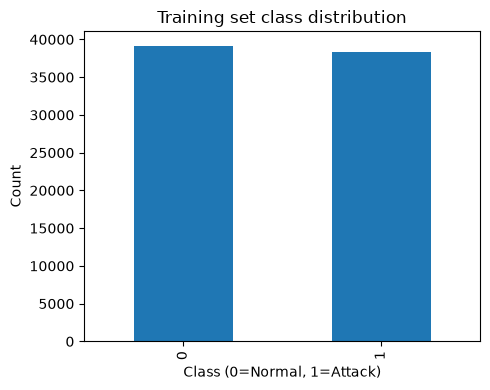

In [33]:
class_counts_train = pd.Series(y_train).value_counts().sort_index()
imbalance_ratio = class_counts_train.max() / class_counts_train.min()

print("Training set class counts:", class_counts_train.to_dict())
print(f"Imbalance ratio (majority:minority): {imbalance_ratio:.2f} : 1")

class_counts_train.plot(kind="bar", figsize=(5, 4), title="Training set class distribution")
plt.xlabel("Class (0=Normal, 1=Attack)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [34]:
# Class weights — an alternative, no-resampling way to handle imbalance.
# Computed here for reference; not used downstream (SMOTE and GAN are the
# two resampling strategies actually compared in this notebook).
class_weights_array = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights_array))
print("Computed class weights:", class_weight_dict)

Computed class weights: {np.int8(0): np.float64(0.9901188802249776), np.int8(1): np.float64(1.0100803296645975)}


## 14. Feature Selection

Correlation analysis on the encoded (pre-scaling) training features, followed
by a quick Random Forest importance pass, then dropping redundant features.
Correlation is invariant to standardization, so it's computed on `X_train`
directly and the resulting column list is applied to the already-scaled
arrays by index — done before any resampling, so SMOTE and the GAN both
oversample only the features that survive selection.

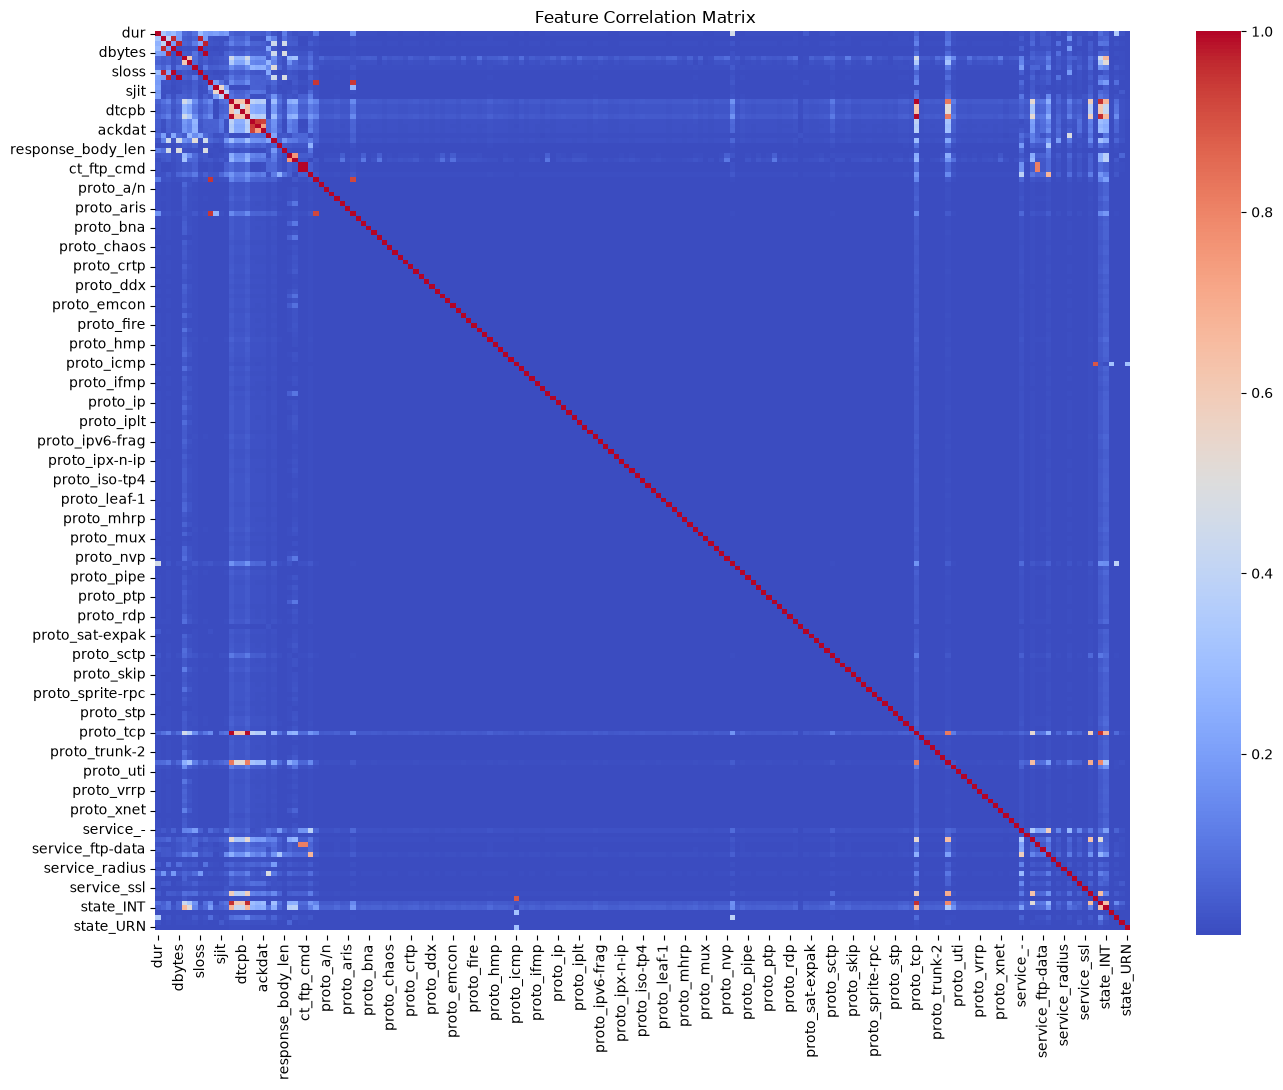

In [35]:
corr_matrix = X_train.corr().abs()

plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, cmap="coolwarm", cbar=True)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [36]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
highly_correlated_pairs = [
    (col, row, upper.loc[row, col])
    for col in upper.columns
    for row in upper.index
    if pd.notna(upper.loc[row, col]) and upper.loc[row, col] > 0.95
]
print(f"Found {len(highly_correlated_pairs)} feature pairs with correlation > 0.95")
for col, row, val in highly_correlated_pairs[:20]:
    print(f"  {row}  <->  {col}   corr={val:.3f}")

Found 13 feature pairs with correlation > 0.95
  spkts  <->  sbytes   corr=0.967
  dpkts  <->  dbytes   corr=0.969
  spkts  <->  sloss   corr=0.974
  sbytes  <->  sloss   corr=0.997
  dpkts  <->  dloss   corr=0.976
  dbytes  <->  dloss   corr=0.996
  swin  <->  dwin   corr=0.992
  is_ftp_login  <->  ct_ftp_cmd   corr=1.000
  swin  <->  proto_tcp   corr=1.000
  dwin  <->  proto_tcp   corr=0.992
  swin  <->  state_FIN   corr=0.957
  dwin  <->  state_FIN   corr=0.964
  proto_tcp  <->  state_FIN   corr=0.957


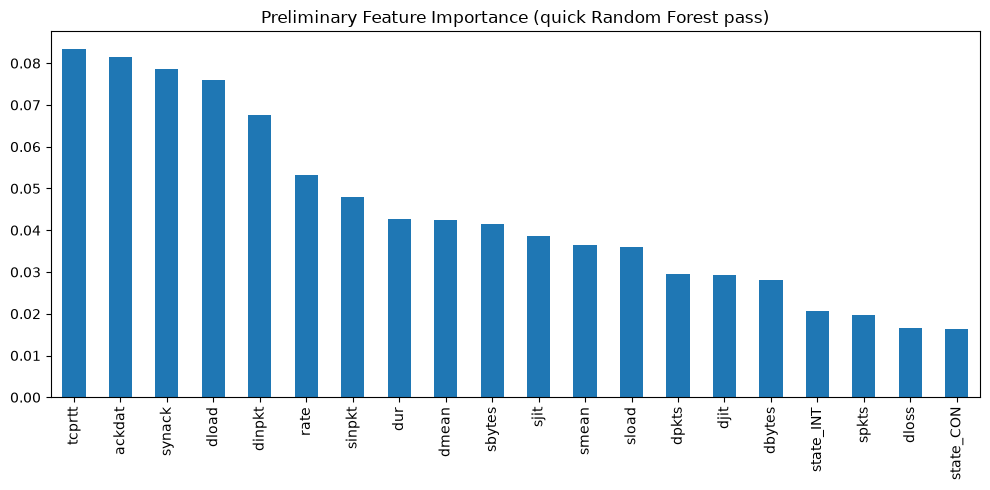

In [37]:
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_train_scaled, y_train)

quick_importance = pd.Series(quick_rf.feature_importances_, index=feature_columns)
quick_importance.sort_values(ascending=False).head(20).plot(
    kind="bar", figsize=(10, 5), title="Preliminary Feature Importance (quick Random Forest pass)"
)
plt.tight_layout()
plt.show()

In [38]:
# Remove redundant features: for each highly-correlated pair, drop whichever of the
# two has the LOWER preliminary importance from the quick Random Forest pass above.
to_drop = set()
for col, row, _ in highly_correlated_pairs:
    loser = col if quick_importance.get(col, 0) < quick_importance.get(row, 0) else row
    to_drop.add(loser)

print(f"Dropping {len(to_drop)} redundant features:", sorted(to_drop))

keep_idx = [i for i, c in enumerate(feature_columns) if c not in to_drop]
feature_columns_selected = [feature_columns[i] for i in keep_idx]

X_train_scaled_sel = X_train_scaled[:, keep_idx]   # original (imbalanced), scaled, selected
X_val_scaled_sel = X_val_scaled[:, keep_idx]
X_test_scaled_sel = X_test_scaled[:, keep_idx]

print("Feature count before selection:", len(feature_columns))
print("Feature count after selection :", len(feature_columns_selected))

Dropping 8 redundant features: ['ct_ftp_cmd', 'dbytes', 'dloss', 'dwin', 'proto_tcp', 'sloss', 'spkts', 'swin']
Feature count before selection: 186
Feature count after selection : 178


## 15. BASELINE — Original Data

All five models trained directly on the original, imbalanced, feature-selected
training set — the true "no resampling" baseline that Steps 16 and 17-18 are
compared against in Step 23.

In [39]:
baseline_original_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        eval_metric="logloss", random_state=42, n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200, max_depth=-1, learning_rate=0.1,
        random_state=42, n_jobs=-1, verbosity=-1,
    ),
}

results = {}
fitted_models = {}

for name, clf in baseline_original_models.items():
    clf.fit(X_train_scaled_sel, y_train)
    y_pred = clf.predict(X_val_scaled_sel)

    results[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
    }
    fitted_models[name] = clf

    print(f"=== {name} (original, imbalanced data) ===")
    print(classification_report(y_val, y_pred, target_names=["Normal", "Attack"]))

=== Logistic Regression (original, imbalanced data) ===
              precision    recall  f1-score   support

      Normal       0.92      0.81      0.86      9779
      Attack       0.83      0.93      0.87      9586

    accuracy                           0.87     19365
   macro avg       0.87      0.87      0.87     19365
weighted avg       0.87      0.87      0.87     19365

=== Decision Tree (original, imbalanced data) ===
              precision    recall  f1-score   support

      Normal       0.90      0.91      0.91      9779
      Attack       0.90      0.90      0.90      9586

    accuracy                           0.90     19365
   macro avg       0.90      0.90      0.90     19365
weighted avg       0.90      0.90      0.90     19365

=== Random Forest (original, imbalanced data) ===
              precision    recall  f1-score   support

      Normal       0.94      0.89      0.92      9779
      Attack       0.90      0.95      0.92      9586

    accuracy              

## 16. SMOTE BASELINE

SMOTE applied to the same feature-selected training set from Step 14/15, then
Random Forest, XGBoost, LightGBM and a soft-voting ensemble trained on the
resampled data.

In [40]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled_sel, y_train_resampled = smote.fit_resample(X_train_scaled_sel, y_train)

print("Before SMOTE:", pd.Series(y_train).value_counts().to_dict())
print("After  SMOTE:", pd.Series(y_train_resampled).value_counts().to_dict())

smote_models = {
    "Random Forest (SMOTE)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost (SMOTE)": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        eval_metric="logloss", random_state=42, n_jobs=-1,
    ),
    "LightGBM (SMOTE)": LGBMClassifier(
        n_estimators=200, max_depth=-1, learning_rate=0.1,
        random_state=42, n_jobs=-1, verbosity=-1,
    ),
}

for name, clf in smote_models.items():
    clf.fit(X_train_resampled_sel, y_train_resampled)
    y_pred = clf.predict(X_val_scaled_sel)

    results[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
    }
    fitted_models[name] = clf

    print(f"=== {name} ===")
    print(classification_report(y_val, y_pred, target_names=["Normal", "Attack"]))

Before SMOTE: {0: 39115, 1: 38342}
After  SMOTE: {0: 39115, 1: 39115}
=== Random Forest (SMOTE) ===
              precision    recall  f1-score   support

      Normal       0.95      0.89      0.92      9779
      Attack       0.90      0.95      0.92      9586

    accuracy                           0.92     19365
   macro avg       0.92      0.92      0.92     19365
weighted avg       0.92      0.92      0.92     19365

=== XGBoost (SMOTE) ===
              precision    recall  f1-score   support

      Normal       0.95      0.89      0.92      9779
      Attack       0.90      0.95      0.92      9586

    accuracy                           0.92     19365
   macro avg       0.92      0.92      0.92     19365
weighted avg       0.92      0.92      0.92     19365

=== LightGBM (SMOTE) ===
              precision    recall  f1-score   support

      Normal       0.95      0.90      0.92      9779
      Attack       0.90      0.95      0.93      9586

    accuracy                     

In [41]:
voting_clf_smote = VotingClassifier(
    estimators=[
        ("rf", fitted_models["Random Forest (SMOTE)"]),
        ("xgb", fitted_models["XGBoost (SMOTE)"]),
        ("lgbm", fitted_models["LightGBM (SMOTE)"]),
    ],
    voting="soft",
)
voting_clf_smote.fit(X_train_resampled_sel, y_train_resampled)
y_pred_voting_smote = voting_clf_smote.predict(X_val_scaled_sel)

results["Voting Ensemble (SMOTE, RF+XGB+LGBM)"] = {
    "accuracy": accuracy_score(y_val, y_pred_voting_smote),
    "precision": precision_score(y_val, y_pred_voting_smote),
    "recall": recall_score(y_val, y_pred_voting_smote),
    "f1": f1_score(y_val, y_pred_voting_smote),
}
fitted_models["Voting Ensemble (SMOTE, RF+XGB+LGBM)"] = voting_clf_smote

print(classification_report(y_val, y_pred_voting_smote, target_names=["Normal", "Attack"]))

              precision    recall  f1-score   support

      Normal       0.95      0.89      0.92      9779
      Attack       0.90      0.95      0.92      9586

    accuracy                           0.92     19365
   macro avg       0.92      0.92      0.92     19365
weighted avg       0.92      0.92      0.92     19365



## 17. GAN Oversampling

In [42]:
# Run once per environment. Skip if torch is already installed.
! pip install torch --quiet

In [43]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.decomposition import PCA

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


### 17.1 Prepare minority data

In [44]:
# X_train_scaled_sel and feature_columns_selected already exist from Step 14/15 —
# no need to re-derive them here.
y_train_arr = np.asarray(y_train)

class_counts = pd.Series(y_train_arr).value_counts()
minority_label = class_counts.idxmin()
majority_label = class_counts.idxmax()
minority_count = int(class_counts[minority_label])
majority_count = int(class_counts[majority_label])
n_to_generate = majority_count - minority_count

X_minority = X_train_scaled_sel[y_train_arr == minority_label]

print(f"Minority class: {minority_label} ({minority_count} samples)")
print(f"Majority class: {majority_label} ({majority_count} samples)")
print(f"Synthetic samples needed to balance: {n_to_generate}")

Minority class: 1 (38342 samples)
Majority class: 0 (39115 samples)
Synthetic samples needed to balance: 773


### 17.2 Train GAN (WGAN-GP)

Wasserstein GAN with gradient penalty — more stable than a vanilla GAN
(avoids the discriminator collapse seen in the from-scratch NumPy version).

Epoch 100/500 | critic loss: -3.5771 | gen loss: 0.1382
Epoch 200/500 | critic loss: -6.5945 | gen loss: -1.0050
Epoch 300/500 | critic loss: -7.5354 | gen loss: -1.4109
Epoch 400/500 | critic loss: -5.6180 | gen loss: -1.5556
Epoch 500/500 | critic loss: -6.7338 | gen loss: -1.6529


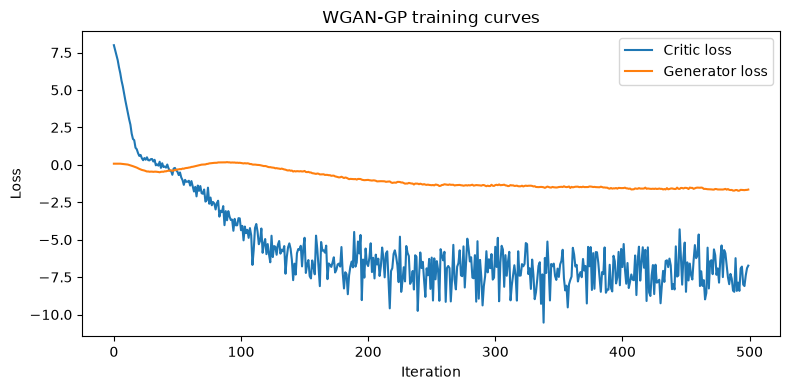

In [45]:
n_features = X_minority.shape[1]
latent_dim = 32

class Generator(nn.Module):
    def __init__(self, latent_dim, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, n_features),
        )

    def forward(self, z):
        return self.net(z)

class Critic(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.net(x)

generator = Generator(latent_dim, n_features).to(device)
critic = Critic(n_features).to(device)

g_opt = optim.Adam(generator.parameters(), lr=1e-4, betas=(0.5, 0.9))
c_opt = optim.Adam(critic.parameters(), lr=1e-4, betas=(0.5, 0.9))

X_minority_t = torch.tensor(X_minority, dtype=torch.float32, device=device)


def gradient_penalty(critic, real, fake, device):
    batch_size = real.size(0)
    epsilon = torch.rand(batch_size, 1, device=device)
    interpolated = (epsilon * real + (1 - epsilon) * fake).requires_grad_(True)
    scores = critic(interpolated)
    grads = torch.autograd.grad(
        outputs=scores, inputs=interpolated,
        grad_outputs=torch.ones_like(scores),
        create_graph=True, retain_graph=True,
    )[0]
    grad_norm = grads.view(batch_size, -1).norm(2, dim=1)
    return ((grad_norm - 1) ** 2).mean()


n_epochs = 500
batch_size = min(128, X_minority_t.shape[0])
n_critic = 5
lambda_gp = 10.0

history = {"critic_loss": [], "gen_loss": []}

for epoch in range(n_epochs):
    idx = torch.randint(0, X_minority_t.shape[0], (batch_size,))
    real = X_minority_t[idx]

    for _ in range(n_critic):
        z = torch.randn(batch_size, latent_dim, device=device)
        fake = generator(z).detach()

        c_opt.zero_grad()
        gp = gradient_penalty(critic, real, fake, device)
        c_loss = critic(fake).mean() - critic(real).mean() + lambda_gp * gp
        c_loss.backward()
        c_opt.step()

    z = torch.randn(batch_size, latent_dim, device=device)
    fake = generator(z)
    g_opt.zero_grad()
    g_loss = -critic(fake).mean()
    g_loss.backward()
    g_opt.step()

    history["critic_loss"].append(c_loss.item())
    history["gen_loss"].append(g_loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}/{n_epochs} | critic loss: {c_loss.item():.4f} | gen loss: {g_loss.item():.4f}")

plt.figure(figsize=(8, 4))
plt.plot(history["critic_loss"], label="Critic loss")
plt.plot(history["gen_loss"], label="Generator loss")
plt.title("WGAN-GP training curves")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

### 17.3 Generate synthetic samples

In [46]:
generator.eval()
with torch.no_grad():
    z = torch.randn(n_to_generate, latent_dim, device=device)
    X_synthetic = generator(z).cpu().numpy()
generator.train()

y_synthetic = np.full(n_to_generate, minority_label)

print(f"Generated {X_synthetic.shape[0]} synthetic '{minority_label}'-class samples "
      f"with {X_synthetic.shape[1]} features")

Generated 773 synthetic '1'-class samples with 178 features


### 17.4 Validate synthetic data

A PCA projection to check the synthetic points land inside the real
minority-class cloud (not scattered randomly, not collapsed to one point),
plus a feature-wise mean/std sanity check.

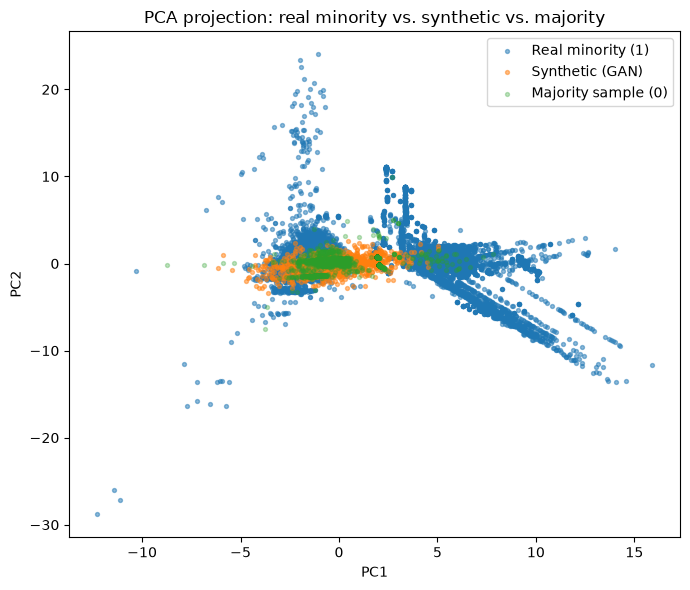

Mean absolute difference in feature means (real vs synthetic): 0.0470
Mean absolute difference in feature stds  (real vs synthetic): 1.0255
Smaller is better — large values suggest the GAN hasn't converged (consider more epochs or a lower critic learning rate).


In [47]:
pca = PCA(n_components=2, random_state=42)

rng = np.random.RandomState(42)
majority_idx = rng.choice(
    np.where(y_train_arr == majority_label)[0],
    size=min(2000, majority_count), replace=False,
)
X_majority_sample = X_train_scaled_sel[majority_idx]

pca_input = np.vstack([X_minority, X_synthetic, X_majority_sample])
pca_coords = pca.fit_transform(pca_input)

n_min, n_syn = len(X_minority), len(X_synthetic)

plt.figure(figsize=(7, 6))
plt.scatter(*pca_coords[:n_min].T, s=8, alpha=0.5, label=f"Real minority ({minority_label})")
plt.scatter(*pca_coords[n_min:n_min + n_syn].T, s=8, alpha=0.5, label="Synthetic (GAN)")
plt.scatter(*pca_coords[n_min + n_syn:].T, s=8, alpha=0.3, label=f"Majority sample ({majority_label})")
plt.title("PCA projection: real minority vs. synthetic vs. majority")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.show()

real_mean, real_std = X_minority.mean(axis=0), X_minority.std(axis=0)
syn_mean, syn_std = X_synthetic.mean(axis=0), X_synthetic.std(axis=0)
mean_diff = np.abs(real_mean - syn_mean).mean()
std_diff = np.abs(real_std - syn_std).mean()

print(f"Mean absolute difference in feature means (real vs synthetic): {mean_diff:.4f}")
print(f"Mean absolute difference in feature stds  (real vs synthetic): {std_diff:.4f}")
print("Smaller is better — large values suggest the GAN hasn't converged "
      "(consider more epochs or a lower critic learning rate).")

### 17.5 Create GAN-balanced dataset

In [48]:
X_train_gan_sel = np.vstack([X_train_scaled_sel, X_synthetic])
y_train_gan = np.concatenate([y_train_arr, y_synthetic])

print("Before GAN oversampling:", pd.Series(y_train_arr).value_counts().to_dict())
print("After  GAN oversampling:", pd.Series(y_train_gan).value_counts().to_dict())

Before GAN oversampling: {0: 39115, 1: 38342}
After  GAN oversampling: {0: 39115, 1: 39115}


## 18. GAN-Based Classification

In [49]:
gan_models = {
    "Random Forest (GAN)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost (GAN)": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        eval_metric="logloss", random_state=42, n_jobs=-1,
    ),
    "LightGBM (GAN)": LGBMClassifier(
        n_estimators=200, max_depth=-1, learning_rate=0.1,
        random_state=42, n_jobs=-1, verbosity=-1,
    ),
}

for name, clf in gan_models.items():
    clf.fit(X_train_gan_sel, y_train_gan)
    y_pred = clf.predict(X_val_scaled_sel)

    results[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
    }
    fitted_models[name] = clf

pd.DataFrame(results).T.loc[list(gan_models.keys())]

,accuracy,precision,recall,f1
Random Forest (GAN),0.918719,0.896085,0.945441,0.920102
XGBoost (GAN),0.923419,0.899517,0.951596,0.924824
LightGBM (GAN),0.924141,0.903309,0.948258,0.925238


In [50]:
voting_clf_gan = VotingClassifier(
    estimators=[
        ("rf", fitted_models["Random Forest (GAN)"]),
        ("xgb", fitted_models["XGBoost (GAN)"]),
        ("lgbm", fitted_models["LightGBM (GAN)"]),
    ],
    voting="soft",
)
voting_clf_gan.fit(X_train_gan_sel, y_train_gan)
y_pred_voting_gan = voting_clf_gan.predict(X_val_scaled_sel)

results["Voting Ensemble (GAN, RF+XGB+LGBM)"] = {
    "accuracy": accuracy_score(y_val, y_pred_voting_gan),
    "precision": precision_score(y_val, y_pred_voting_gan),
    "recall": recall_score(y_val, y_pred_voting_gan),
    "f1": f1_score(y_val, y_pred_voting_gan),
}
fitted_models["Voting Ensemble (GAN, RF+XGB+LGBM)"] = voting_clf_gan

pd.DataFrame(results).T.tail(4)

,accuracy,precision,recall,f1
Random Forest (GAN),0.918719,0.896085,0.945441,0.920102
XGBoost (GAN),0.923419,0.899517,0.951596,0.924824
LightGBM (GAN),0.924141,0.903309,0.948258,0.925238
"Voting Ensemble (GAN, RF+XGB+LGBM)",0.922334,0.896877,0.952639,0.923917


## 19. Hyperparameter Tuning

`RandomizedSearchCV` for a broad search over Random Forest, then
`GridSearchCV` for a focused search over XGBoost — both on the SMOTE-balanced
training set, both scored on F1 for the Attack class.

In [51]:
rf_param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=10, scoring="f1", cv=3, random_state=42, n_jobs=-1,
)
rf_search.fit(X_train_resampled_sel, y_train_resampled)

print("Best RF params (RandomizedSearchCV):", rf_search.best_params_)
print("Best RF CV F1:", rf_search.best_score_)

best_rf = rf_search.best_estimator_
fitted_models["Random Forest (tuned)"] = best_rf

Best RF params (RandomizedSearchCV): {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 30}
Best RF CV F1: 0.9230009795766825


In [52]:
xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [4, 6],
    "learning_rate": [0.05, 0.1],
}

xgb_search = GridSearchCV(
    XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1),
    param_grid=xgb_param_grid,
    scoring="f1", cv=3, n_jobs=-1,
)
xgb_search.fit(X_train_resampled_sel, y_train_resampled)

print("Best XGBoost params (GridSearchCV):", xgb_search.best_params_)
print("Best XGBoost CV F1:", xgb_search.best_score_)

best_xgb = xgb_search.best_estimator_
fitted_models["XGBoost (tuned)"] = best_xgb

Best XGBoost params (GridSearchCV): {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200}
Best XGBoost CV F1: 0.9235024763667138


In [53]:
for name, clf in [("Random Forest (tuned)", best_rf), ("XGBoost (tuned)", best_xgb)]:
    y_pred = clf.predict(X_val_scaled_sel)
    results[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
    }

## 20. Feature Importance (Random Forest, XGBoost, LightGBM)

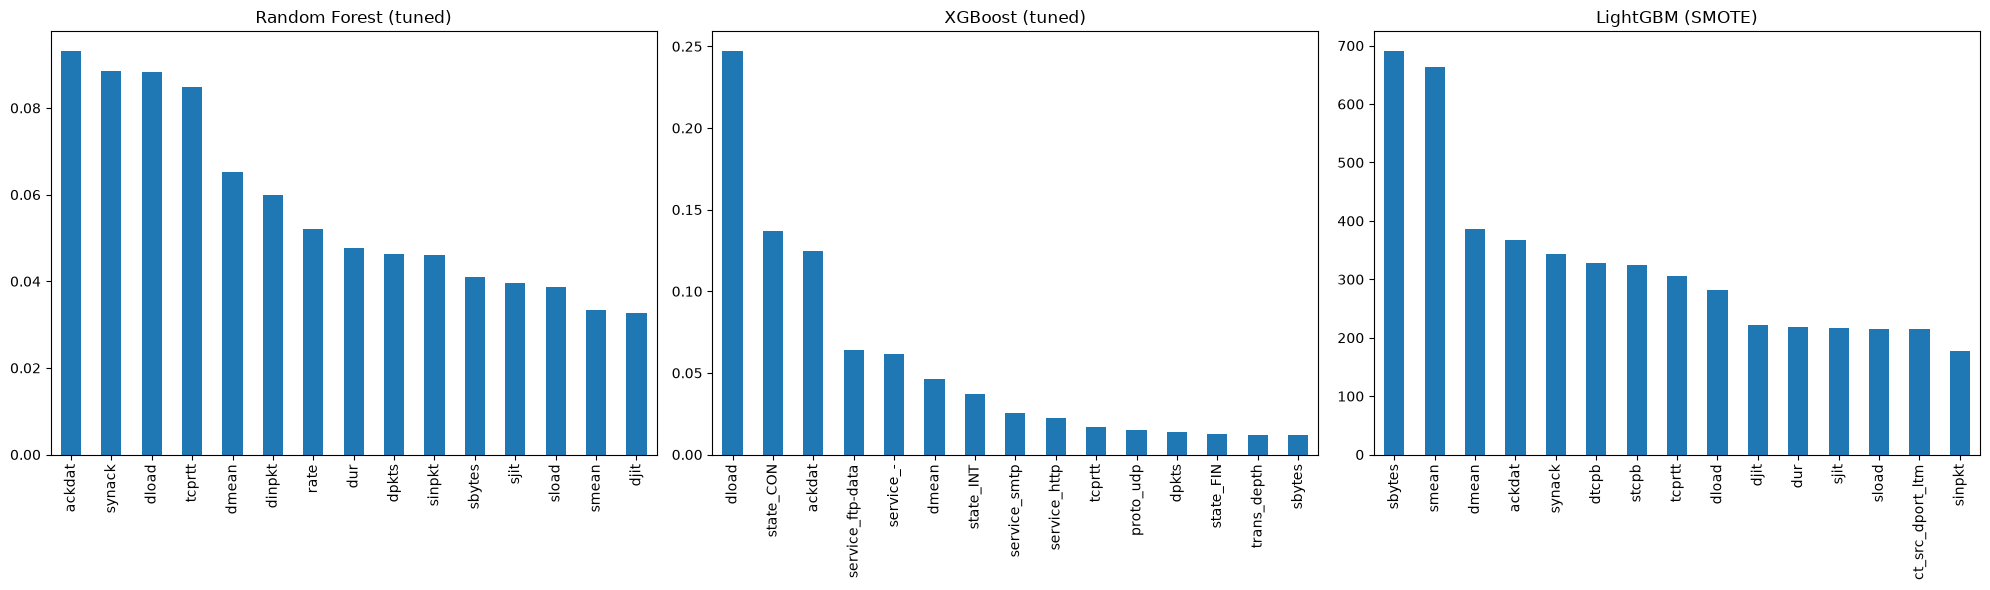

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

importance_rf = pd.Series(best_rf.feature_importances_, index=feature_columns_selected)
importance_rf.sort_values(ascending=False).head(15).plot(kind="bar", ax=axes[0], title="Random Forest (tuned)")

importance_xgb = pd.Series(best_xgb.feature_importances_, index=feature_columns_selected)
importance_xgb.sort_values(ascending=False).head(15).plot(kind="bar", ax=axes[1], title="XGBoost (tuned)")

importance_lgbm = pd.Series(fitted_models["LightGBM (SMOTE)"].feature_importances_, index=feature_columns_selected)
importance_lgbm.sort_values(ascending=False).head(15).plot(kind="bar", ax=axes[2], title="LightGBM (SMOTE)")

plt.tight_layout()
plt.show()

## 21. SHAP Explainability

Global feature importance via `summary_plot`, plus an individual-prediction
explanation via a waterfall plot for one validation sample, on the tuned
Random Forest.

Global feature importance (SHAP):


C:\Users\Surya\AppData\Local\Temp\ipykernel_12380\767271544.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_attack, shap_sample_df, show=True)
e:\BRM003-ML-Project\brmenv\Lib\site-packages\shap\plots\_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
e:\BRM003-ML-Project\brmenv\Lib\site-packages\shap\plots\_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(


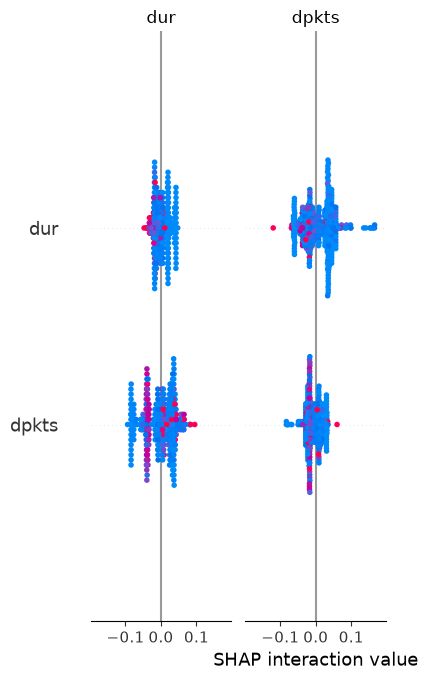

In [55]:
explainer = shap.TreeExplainer(best_rf)

shap_sample_df = pd.DataFrame(X_val_scaled_sel, columns=feature_columns_selected).sample(
    n=min(500, len(X_val)), random_state=42
)
shap_values = explainer.shap_values(shap_sample_df)

sv_attack = shap_values[1] if isinstance(shap_values, list) else shap_values

print("Global feature importance (SHAP):")
shap.summary_plot(sv_attack, shap_sample_df, show=True)

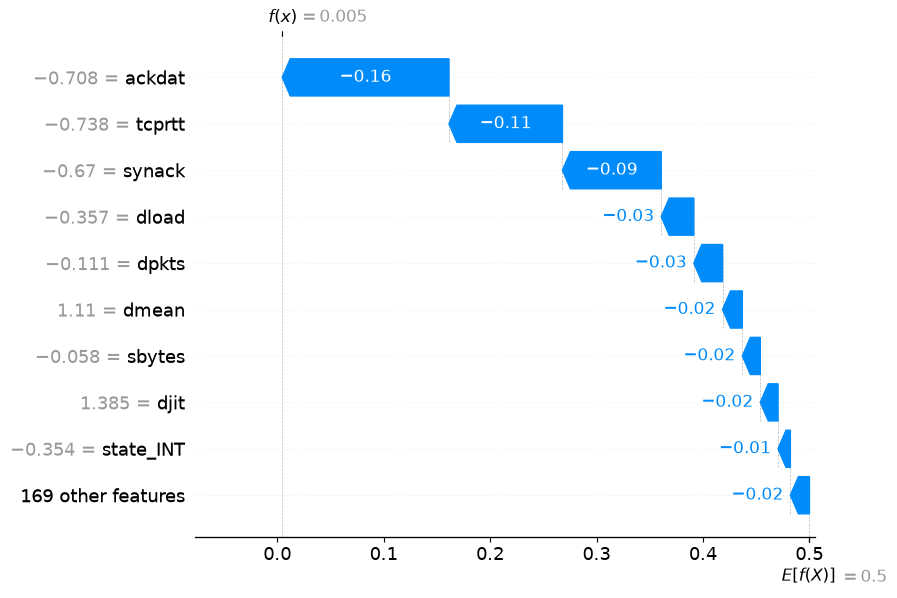

In [56]:
# Individual prediction explanation — first row of the SHAP sample
instance_idx = 0
sv_instance = sv_attack[instance_idx]

expected_value = explainer.expected_value
expected_value = expected_value[1] if isinstance(expected_value, (list, np.ndarray)) and np.ndim(expected_value) > 0 else expected_value

explanation = shap.Explanation(
    values=sv_instance,
    base_values=expected_value,
    data=shap_sample_df.iloc[instance_idx].values,
    feature_names=feature_columns_selected,
)

# Select the Attack-class SHAP values for this single instance
sv_instance = np.asarray(sv_instance)
if sv_instance.ndim == 2:
    sv_instance = sv_instance[:, 1]

explanation = shap.Explanation(
    values=sv_instance,
    base_values=expected_value,
    data=shap_sample_df.iloc[instance_idx].values,
    feature_names=feature_columns_selected,
)

shap.plots.waterfall(explanation, show=True)

## 22. Validation Evaluation

In [57]:
best_model_name = pd.DataFrame(results).T["f1"].idxmax()
best_model = fitted_models[best_model_name]
print("Best model on validation set:", best_model_name)

y_pred_best = best_model.predict(X_val_scaled_sel)
prob_best = best_model.predict_proba(X_val_scaled_sel)[:, 1]

print(classification_report(y_val, y_pred_best, target_names=["Normal", "Attack"]))
print("ROC-AUC:", roc_auc_score(y_val, prob_best))
print("PR-AUC (average precision):", average_precision_score(y_val, prob_best))

Best model on validation set: XGBoost
              precision    recall  f1-score   support

      Normal       0.95      0.90      0.92      9779
      Attack       0.90      0.95      0.93      9586

    accuracy                           0.92     19365
   macro avg       0.93      0.92      0.92     19365
weighted avg       0.93      0.92      0.92     19365

ROC-AUC: 0.9833453262436804
PR-AUC (average precision): 0.981858544872577


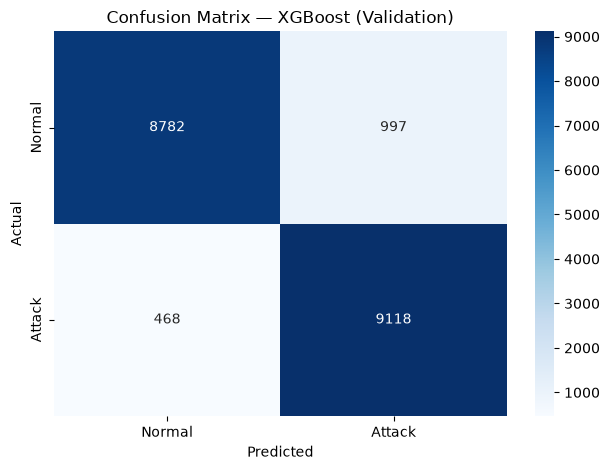

In [58]:
cm = confusion_matrix(y_val, y_pred_best)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_model_name} (Validation)")
plt.tight_layout()
plt.show()

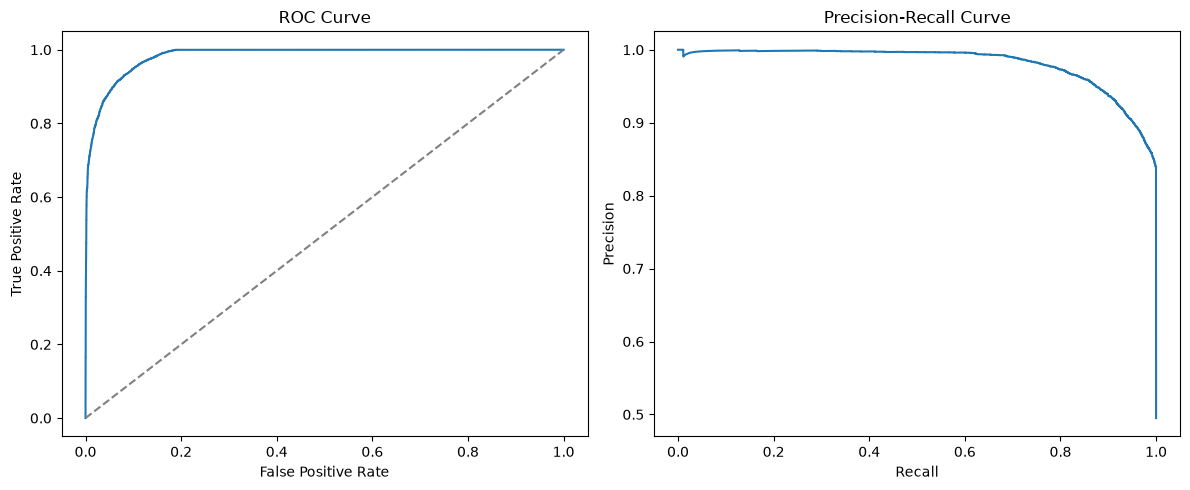

In [59]:
fpr, tpr, _ = roc_curve(y_val, prob_best)
precision_curve, recall_curve, _ = precision_recall_curve(y_val, prob_best)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

axes[1].plot(recall_curve, precision_curve)
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

plt.tight_layout()
plt.show()

## 23. Original vs SMOTE vs GAN

A genuine three-way comparison — Step 15's models never saw resampled data,
so this is a fair fight.

In [60]:
strategy_groups = {
    "Original": [
        "Logistic Regression", "Decision Tree", "Random Forest", "XGBoost", "LightGBM",
    ],
    "SMOTE": [
        "Random Forest (SMOTE)", "XGBoost (SMOTE)", "LightGBM (SMOTE)",
        "Voting Ensemble (SMOTE, RF+XGB+LGBM)",
        "Random Forest (tuned)", "XGBoost (tuned)",
    ],
    "GAN": [
        "Random Forest (GAN)", "XGBoost (GAN)", "LightGBM (GAN)",
        "Voting Ensemble (GAN, RF+XGB+LGBM)",
    ],
}

comparison_rows = []
for strategy, model_names in strategy_groups.items():
    for name in model_names:
        if name in results:
            row = {"strategy": strategy, "model": name}
            row.update(results[name])
            comparison_rows.append(row)

comparison_df3 = pd.DataFrame(comparison_rows).set_index(["strategy", "model"])
comparison_df3.sort_values(["strategy", "f1"], ascending=[True, False])

accuracy  precision    recall  \
strategy model                                                                 
GAN      LightGBM (GAN)                        0.924141   0.903309  0.948258   
         XGBoost (GAN)                         0.923419   0.899517  0.951596   
         Voting Ensemble (GAN, RF+XGB+LGBM)    0.922334   0.896877  0.952639   
         Random Forest (GAN)                   0.918719   0.896085  0.945441   
Original XGBoost                               0.924348   0.901434  0.951179   
         LightGBM                              0.924503   0.903376  0.948988   
         Random Forest                         0.919804   0.897084  0.946589   
         Decision Tree                         0.904054   0.904523  0.901314   
         Logistic Regression                   0.867906   0.825009  0.930524   
SMOTE    LightGBM (SMOTE)                      0.924141   0.901712  0.950344   
         XGBoost (SMOTE)                       0.922747   0.897738  0.952431   
         XGBoost (tuned)                       0.922747   0.897738  0.952431   
         Voting Ensemble (SMOTE, RF+XGB+LGBM)  0.922644   0.896704  0.953578   
         Random Forest (tuned)                 0.919649   0.881581  0.967661   
         Random Forest (SMOTE)                 0.920372   0.896100  0.949197   

                                                     f1  
strategy model                                           
GAN      LightGBM (GAN)                        0.925238  
         XGBoost (GAN)                         0.924824  
         Voting Ensemble (GAN, RF+XGB+LGBM)    0.923917  
         Random Forest (GAN)                   0.920102  
Original XGBoost                               0.925638  
         LightGBM                              0.925621  
         Random Forest                         0.921172  
         Decision Tree                         0.902916  
         Logistic Regression                   0.874596  
SMOTE    LightGBM (SMOTE)                      0.925390  
         XGBoost (SMOTE)                       0.924276  
         XGBoost (tuned)                       0.924276  
         Voting Ensemble (SMOTE, RF+XGB+LGBM)  0.924267  
         Random Forest (tuned)                 0.922618  
         Random Forest (SMOTE)                 0.921884

In [61]:
best_per_strategy = (
    comparison_df3.reset_index()
    .sort_values("f1", ascending=False)
    .groupby("strategy")
    .first()
)
print("Best model per balancing strategy (by validation F1):")
best_per_strategy[["model", "f1", "recall", "precision", "accuracy"]]

Best model per balancing strategy (by validation F1):


,model,f1,recall,precision,accuracy
strategy,,,,,
GAN,LightGBM (GAN),0.925238,0.948258,0.903309,0.924141
Original,XGBoost,0.925638,0.951179,0.901434,0.924348
SMOTE,LightGBM (SMOTE),0.925390,0.950344,0.901712,0.924141


## 24. Final Evaluation on UNSW-NB15 Test Set

In [62]:
y_pred_test = best_model.predict(X_test_scaled_sel)
prob_test = best_model.predict_proba(X_test_scaled_sel)[:, 1]

print(f"=== {best_model_name} — UNSW-NB15 Test Set (held-out) ===")
print(classification_report(y_test, y_pred_test, target_names=["Normal", "Attack"]))
print("Test ROC-AUC:", roc_auc_score(y_test, prob_test))
print("Test PR-AUC :", average_precision_score(y_test, prob_test))

=== XGBoost — UNSW-NB15 Test Set (held-out) ===
              precision    recall  f1-score   support

      Normal       0.96      0.72      0.83     37000
      Attack       0.81      0.98      0.89     45332

    accuracy                           0.86     82332
   macro avg       0.89      0.85      0.86     82332
weighted avg       0.88      0.86      0.86     82332

Test ROC-AUC: 0.9798966695562589
Test PR-AUC : 0.9855705153630948


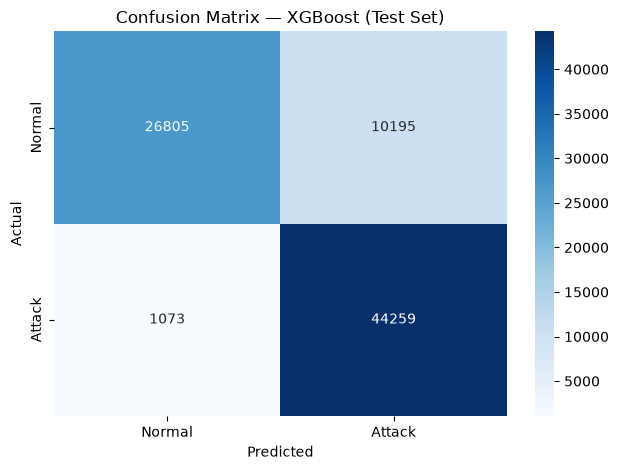

In [63]:
cm_test = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_model_name} (Test Set)")
plt.tight_layout()
plt.show()

## 25. Final Model Comparison

All models across Original, SMOTE and GAN branches, ranked by validation F1,
then the final pick — highest recall + F1 among models with an acceptable
false-positive rate (<= 5%). Accuracy alone is not the selection criterion:
a model that just predicts "Attack" for everything can still score well on
accuracy while being useless operationally, and a high FPR means drowning
analysts in false alarms.

In [64]:
comparison_df = pd.DataFrame(results).T.sort_values("f1", ascending=False)
comparison_df

,accuracy,precision,recall,f1
XGBoost,0.924348,0.901434,0.951179,0.925638
LightGBM,0.924503,0.903376,0.948988,0.925621
LightGBM (SMOTE),0.924141,0.901712,0.950344,0.925390
LightGBM (GAN),0.924141,0.903309,0.948258,0.925238
XGBoost (GAN),0.923419,0.899517,0.951596,0.924824
XGBoost (tuned),0.922747,0.897738,0.952431,0.924276
XGBoost (SMOTE),0.922747,0.897738,0.952431,0.924276
"Voting Ensemble (SMOTE, RF+XGB+LGBM)",0.922644,0.896704,0.953578,0.924267
"Voting Ensemble (GAN, RF+XGB+LGBM)",0.922334,0.896877,0.952639,0.923917
Random Forest (tuned),0.919649,0.881581,0.967661,0.922618


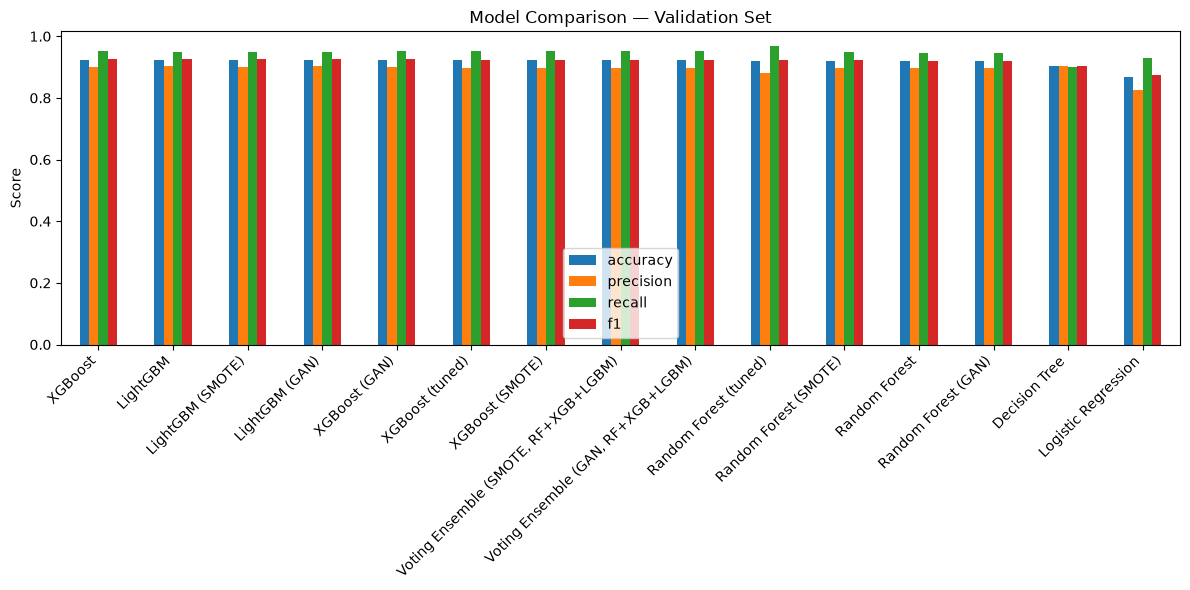

In [65]:
comparison_df[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(12, 6), title="Model Comparison — Validation Set"
)
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [66]:
selection_rows = []
for name, clf in fitted_models.items():
    y_pred_m = clf.predict(X_val_scaled_sel)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_m).ravel()
    fpr_m = fp / (fp + tn) if (fp + tn) > 0 else np.nan

    selection_rows.append({
        "model": name,
        "recall": recall_score(y_val, y_pred_m),
        "f1": f1_score(y_val, y_pred_m),
        "fpr": fpr_m,
    })

selection_df = pd.DataFrame(selection_rows).set_index("model").sort_values(
    ["recall", "f1"], ascending=False
)
selection_df

,recall,f1,fpr
model,,,
Random Forest (tuned),0.967661,0.922618,0.127416
"Voting Ensemble (SMOTE, RF+XGB+LGBM)",0.953578,0.924267,0.107680
"Voting Ensemble (GAN, RF+XGB+LGBM)",0.952639,0.923917,0.107373
XGBoost (SMOTE),0.952431,0.924276,0.106350
XGBoost (tuned),0.952431,0.924276,0.106350
XGBoost (GAN),0.951596,0.924824,0.104203
XGBoost,0.951179,0.925638,0.101953
LightGBM (SMOTE),0.950344,0.925390,0.101544
Random Forest (SMOTE),0.949197,0.921884,0.107884


In [67]:
# Final pick: highest recall + F1 among models with an acceptable false-positive rate (<= 5%)
acceptable = selection_df[selection_df["fpr"] <= 0.05]
final_model_name = (acceptable if not acceptable.empty else selection_df)["f1"].idxmax()
final_model = fitted_models[final_model_name]

print("Selected final model:", final_model_name)
print(selection_df.loc[final_model_name])

Selected final model: XGBoost
recall    0.951179
f1        0.925638
fpr       0.101953
Name: XGBoost, dtype: float64


## 26. Save Model + Preprocessing

In [68]:
joblib.dump(final_model, "final_model_unsw_binary.joblib")
joblib.dump(scaler, "scaler_unsw_binary.joblib")
joblib.dump(feature_columns_selected, "feature_columns_unsw_binary.joblib")
joblib.dump(target_encoder, "target_encoder_unsw_binary.joblib")

print(f"Saved '{final_model_name}' to final_model_unsw_binary.joblib, plus scaler and feature-column list")

Saved 'XGBoost' to final_model_unsw_binary.joblib, plus scaler and feature-column list


## 27. Final Results & Conclusion

In [69]:
print("=== FINAL SUMMARY ===")
print(f"Final model selected: {final_model_name}")
print(selection_df.loc[final_model_name])
print()
print("Held-out UNSW-NB15 test set performance:")
print(f"  ROC-AUC: {roc_auc_score(y_test, prob_test):.4f}")
print(f"  PR-AUC : {average_precision_score(y_test, prob_test):.4f}")
print(f"  F1     : {f1_score(y_test, y_pred_test):.4f}")

=== FINAL SUMMARY ===
Final model selected: XGBoost
recall    0.951179
f1        0.925638
fpr       0.101953
Name: XGBoost, dtype: float64

Held-out UNSW-NB15 test set performance:
  ROC-AUC: 0.9799
  PR-AUC : 0.9856
  F1     : 0.8871


**Conclusion.** Three imbalance-handling strategies were compared on equal
footing — Original (no resampling), SMOTE, and GAN-based oversampling
(WGAN-GP) — each feeding the same Random Forest / XGBoost / LightGBM /
soft-voting ensemble family, all evaluated on the same feature-selected
validation set (Step 23). The final model above was selected by
prioritizing **recall** and **F1 on the Attack class** while keeping the
**false-positive rate** at an operationally acceptable level (Step 25),
rather than by raw accuracy. Correlation-based feature selection (Step 14)
removed redundant features *before* any resampling, so both SMOTE and the
GAN oversample only the features that survive selection. SHAP TreeExplainer
(Step 21) provides both global and per-prediction explanations to support
the trustworthiness case for the framework. The saved artifacts (model,
scaler, selected feature list, target encoder) are sufficient to reproduce
predictions on new UNSW-NB15-formatted traffic without re-running the full
pipeline.

*Scope note:* this notebook covers the **binary** (Normal vs. Attack) branch.
A multiclass companion notebook (Normal + individual attack categories,
using `attack_cat`) can be built the same way — same pipeline, `f1_macro`
scoring, and per-class SHAP — if you'd like it as a separate file.